In [72]:
import numpy as np
import pandas as pd

from scipy.stats import ecdf

from lifelines import KaplanMeierFitter
from lifelines import CoxPHFitter

import matplotlib.pyplot as plt

import testis_modeling2 as tm

In [73]:
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 12,              # base font size
    'xtick.labelsize': 7,        # x-axis tick label size
    'ytick.labelsize': 7,        # y-axis tick label size
    'axes.labelsize': 12,         # axis label size
    'axes.titlesize': 12,         # title size
    'legend.fontsize': 12,        # legend font size
    'figure.titlesize': 12        # figure title size
})

In [74]:
df = pd.read_csv('../../testis-model-analysis/2025-drift-paper/all_clone_results.csv')

In [75]:
df.head()

,scenario,fish,clone,init_time,init_freq,last_time,max_time,max_freq,size,avg_freq_change,r_opt,if_opt,l_max,lower,upper,if_null,l_null
0,n500_r15_y6,0,0,1.0,0.304582,18.0,18.0,0.183288,0.289608,0.007135,21.919817,0.307162,-88.556002,8.503530,68.702417,0.289608,-251.078272
1,n500_r15_y6,0,1,1.0,0.156334,5.0,18.0,0.000000,0.023360,0.037062,24.455399,0.152912,-20.549349,5.447543,146.436829,0.023360,-249.564210
2,n500_r15_y6,0,2,1.0,0.115903,3.0,18.0,0.000000,0.015274,0.041779,47.988718,0.117011,-12.777606,7.574745,473.370544,0.015274,-208.366860
3,n500_r15_y6,0,3,1.0,0.094340,1.0,18.0,0.000000,0.005241,NaN,1000.000000,0.094286,-2.947001,20.938202,NaN,0.005241,-105.426060
4,n500_r15_y6,0,4,1.0,0.088949,2.0,18.0,0.000000,0.006439,0.061995,50.575174,0.088244,-7.588773,6.353441,NaN,0.006439,-107.163524


In [76]:
# Convert sample times to real times.

# At some point this should just be done at an earlier step

In [77]:
# sample_map = tm.data_processing.sample_map_int

# df['max_time'] = df['max_time'].map(sample_map)
# df['last_time'] = df['last_time'].map(sample_map)#.fillna(df['max_time'])

truncate_time = 26
df['last_time'] = np.minimum(truncate_time, df['last_time'])
df['max_time'] = np.minimum(truncate_time, df['max_time'])

df['died_early'] = df['last_time'] != df['max_time']

# df['died_early'] = ~df['last_time'].isna()
# df['last_time'] = df['last_time'].fillna(df['max_time'])
df.head()

,scenario,fish,clone,init_time,init_freq,last_time,max_time,max_freq,size,avg_freq_change,r_opt,if_opt,l_max,lower,upper,if_null,l_null,died_early
0,n500_r15_y6,0,0,1.0,0.304582,18.0,18.0,0.183288,0.289608,0.007135,21.919817,0.307162,-88.556002,8.503530,68.702417,0.289608,-251.078272,False
1,n500_r15_y6,0,1,1.0,0.156334,5.0,18.0,0.000000,0.023360,0.037062,24.455399,0.152912,-20.549349,5.447543,146.436829,0.023360,-249.564210,True
2,n500_r15_y6,0,2,1.0,0.115903,3.0,18.0,0.000000,0.015274,0.041779,47.988718,0.117011,-12.777606,7.574745,473.370544,0.015274,-208.366860,True
3,n500_r15_y6,0,3,1.0,0.094340,1.0,18.0,0.000000,0.005241,NaN,1000.000000,0.094286,-2.947001,20.938202,NaN,0.005241,-105.426060,True
4,n500_r15_y6,0,4,1.0,0.088949,2.0,18.0,0.000000,0.006439,0.061995,50.575174,0.088244,-7.588773,6.353441,NaN,0.006439,-107.163524,True


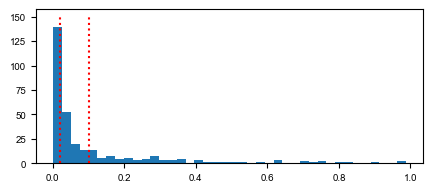

In [78]:
small_cutoff = 0.02
large_cutoff = 0.10

fig, ax = plt.subplots(figsize = (5, 2))

real_df = df.query('scenario == "real"')
ax.hist(real_df['init_freq'], bins=40)
ax.vlines(x=small_cutoff, ymin=0, ymax=150, colors='r', linestyles='dotted', zorder=1)
ax.vlines(x=large_cutoff, ymin=0, ymax=150, colors='r', linestyles='dotted', zorder=1)

In [79]:
print(f"""\
{100*(real_df['init_freq'] < small_cutoff).mean():.1f}% of clones have a size below {small_cutoff:.2f}, \
{100*((real_df['init_freq'] > small_cutoff) & (real_df['init_freq'] < large_cutoff)).mean():.1f}% \
have a size between {small_cutoff:.2f} and {large_cutoff:.2f}, and \
{100*(real_df['init_freq'] > large_cutoff).mean():.1f}% of clones have a size above {large_cutoff:.2f}.\
""")

37.3% of clones have a size below 0.02, 35.9% have a size between 0.02 and 0.10, and 26.8% of clones have a size above 0.10.


In [80]:
df.loc[df['init_freq'] < large_cutoff, 'tertile'] = 'medium'
df.loc[df['init_freq'] < small_cutoff, 'tertile'] = 'small'
df.loc[df['init_freq'] > large_cutoff, 'tertile'] = 'large'

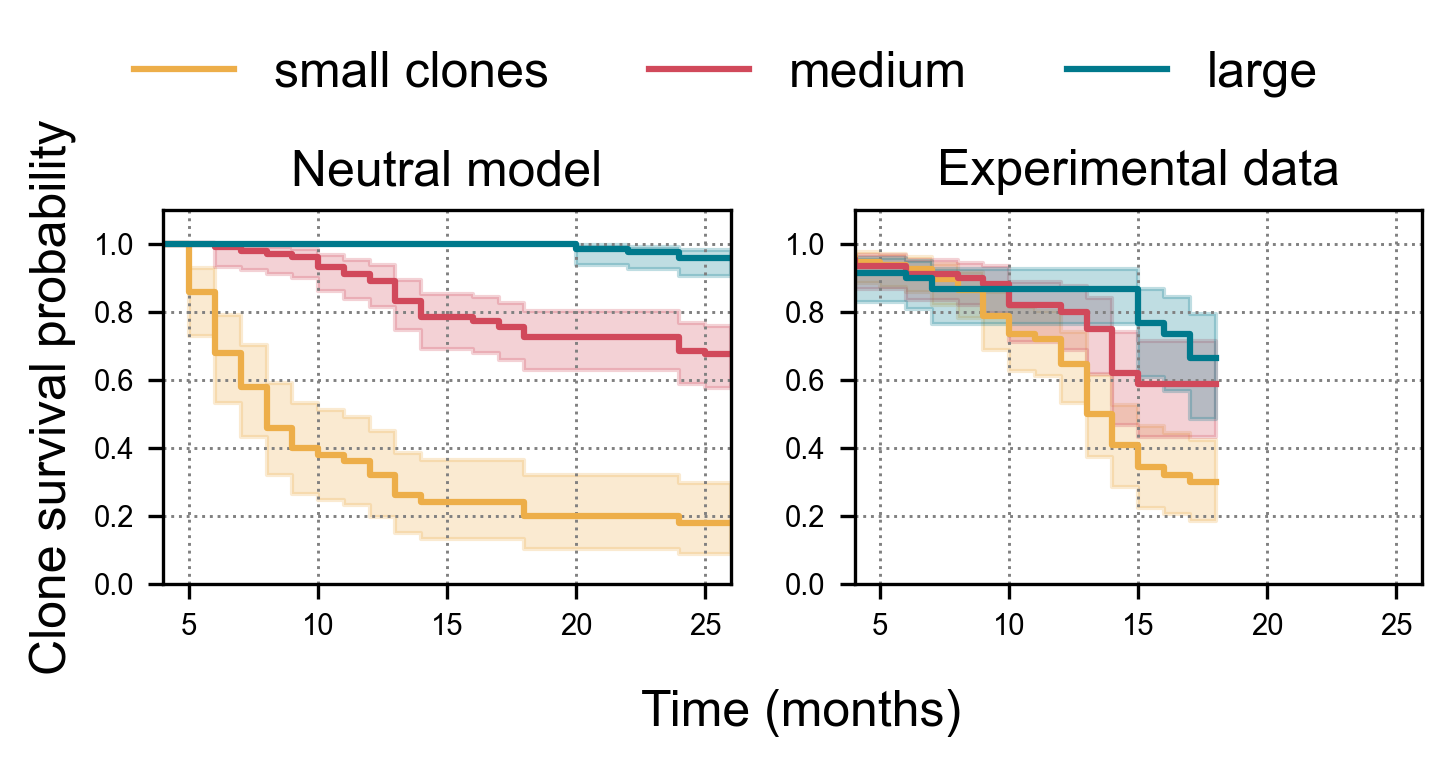

In [81]:
fig, ax = plt.subplots(1, 2, figsize=(5, 2), dpi = 300)

n_experimental_fish = 30
compare_scenario = 'n1000_r2.5_y6'

kmf = dict()
subset = dict()
for i, s in enumerate([compare_scenario, 'real']):
    # Filter the DataFrame
    
    # Instantiate the KaplanMeierFitter
    kmf[s, 'sm'] = KaplanMeierFitter()
    kmf[s, 'md'] = KaplanMeierFitter()
    kmf[s, 'lg'] = KaplanMeierFitter()

    data = df.query('scenario == @s')
    if s == 'real':
        subset[s, 'sm'] = data.query('tertile == "small"')
        subset[s, 'md'] = data.query('tertile == "medium"')
        subset[s, 'lg'] = data.query('tertile == "large"')
    else:
        # subset 'fish <= 30' so that we are comparing similar amounts of
        # experimental & real data.
        subset[s, 'sm'] = data.query('tertile == "small" and fish <= @n_experimental_fish')
        subset[s, 'md'] = data.query('tertile == "medium" and fish <= @n_experimental_fish')
        subset[s, 'lg'] = data.query('tertile == "large" and fish <= @n_experimental_fish')

    sm, md, lg = subset[s, 'sm'], subset[s, 'md'], subset[s, 'lg']
    
    # Fit the model — assuming all events are observed (no censoring)
    kmf[s, 'sm'].fit(durations = sm['last_time'], event_observed = sm['died_early'])
    kmf[s, 'md'].fit(durations = md['last_time'], event_observed = md['died_early'])
    kmf[s, 'lg'].fit(durations = lg['last_time'], event_observed = lg['died_early'])
    
    # Plot the survival curve
    kmf[s, 'sm'].plot_survival_function(ax = ax[i], label='small clones', color = '#edae49')
    kmf[s, 'md'].plot_survival_function(ax = ax[i], label='medium', color = '#d1495b')
    kmf[s, 'lg'].plot_survival_function(ax = ax[i], label='large', color = '#00798c')
    # ax[i].set_title(f'{g}')
    ax[i].set_xlabel('')
    # ax[i].set_ylabel('Survival Probability')
    ax[i].grid(True, linestyle=':', linewidth=0.7, color='gray')
    ax[i].set_xlim([4, 26])
    ax[i].set_ylim([0, 1.1])
    ax[i].set_title('Neutral model' if i == 0 else 'Experimental data')
    ax[i].legend_.remove()
    if i == 0:
        ax[i].set_ylabel('Clone survival probability')

# After plotting all curves
handles, labels = ax[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.15), ncol=3, frameon=False)
fig.text(0.55, -0.03, 'Time (months)', ha='center', va='center', fontsize=12)

plt.tight_layout()
# plt.savefig('./images/survivorship-tertile.png', transparent = True, bbox_inches = 'tight')

In [82]:
df[df['scenario'].isin(['real', compare_scenario])].groupby('scenario').agg({'died_early': 'mean'})
# Slightly more of the simulations died early in this comparison.

,died_early
scenario,
n1000_r2.5_y6,0.290076
real,0.287582


In [83]:
from lifelines import CoxPHFitter

# Subset to relevant scenarios
df_sub = df[df['scenario'].isin(['real', 'n1000_r3_y6'])].copy()

# Ensure 'scenario' is treated as a categorical variable
df_sub['scenario'] = df_sub['scenario'].astype('category')

# Fit Cox model with interaction
cph = CoxPHFitter()
cph.fit(df_sub, duration_col='last_time', event_col='died_early', formula='init_freq * scenario')

# Print results
print("Interaction model: init_freq × scenario")
cph.print_summary()

Interaction model: init_freq × scenario


<lifelines.CoxPHFitter: fitted with 1200 total observations, 813 right-censored observations>
             duration col = 'last_time'
                event col = 'died_early'
      baseline estimation = breslow
   number of observations = 1200
number of events observed = 387
   partial log-likelihood = -2386.35
         time fit was run = 2025-11-10 01:07:05 UTC

---
                             coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                    
init_freq                  -24.69      0.00      1.72          -28.06          -21.32                0.00                0.00
scenario[T.real]            -0.62      0.54      0.16           -0.93           -0.31                0.39                0.73
init_freq:scenario[T.real]  22.54  6.16e+09      1.96           18.71           26.37            1.34e+08            2.85e+11

                            cmp to      z      p  -log2(p)
covariate                                                 
init_freq                     0.00 -14.36 <0.005    152.85
scenario[T.real]              0.00  -3.91 <0.005     13.43
init_freq:scenario[T.real]    0.00  11.53 <0.005     99.75
---
Concordance = 0.82
Partial AIC = 4778.71
log-likelihood ratio test = 458.78 on 3 df
-log2(p) of ll-ratio test = 326.84

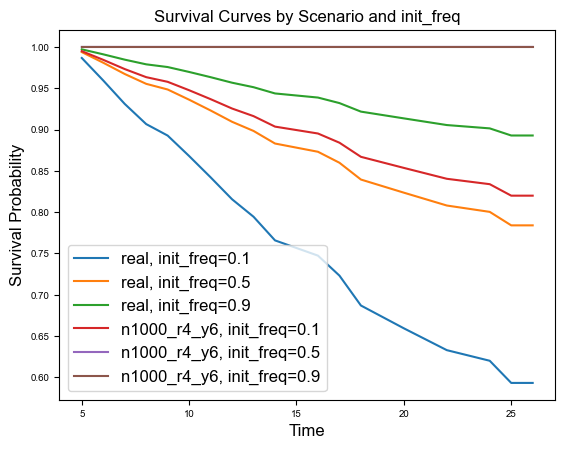

In [20]:
import matplotlib.pyplot as plt

for scenario in ['real', 'n1000_r4_y6']:
    for freq in [0.1, 0.5, 0.9]:
        row = pd.DataFrame({'scenario': [scenario], 'init_freq': [freq]})
        sf = cph.predict_survival_function(row)
        label = f"{scenario}, init_freq={freq}"
        plt.plot(sf.index, sf.values.flatten(), label=label)

plt.legend()
plt.xlabel("Time")
plt.ylabel("Survival Probability")
plt.title("Survival Curves by Scenario and init_freq")
plt.show()

In [261]:
# Cox proportional hazards model with `init_freq` as covariate

# Subset for 'real'
df_real = df[df['scenario'] == 'real']
cph_real = CoxPHFitter()
cph_real.fit(df_real[['last_time', 'died_early', 'init_freq']], duration_col='last_time', event_col='died_early')
print("Results for scenario: real")
cph_real.print_summary()

Results for scenario: real


<lifelines.CoxPHFitter: fitted with 306 total observations, 230 right-censored observations>
             duration col = 'last_time'
                event col = 'died_early'
      baseline estimation = breslow
   number of observations = 306
number of events observed = 76
   partial log-likelihood = -384.29
         time fit was run = 2025-10-30 15:31:34 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
init_freq -2.72      0.07      1.13           -4.94           -0.50                0.01                0.61

           cmp to     z    p  -log2(p)
covariate                             
init_freq    0.00 -2.40 0.02      5.92
---
Concordance = 0.59
Partial AIC = 770.58
log-likelihood ratio test = 8.50 on 1 df
-log2(p) of ll-ratio test = 8.14

In [243]:
# Subset for 'n200_r3_p0_a0'
df_sim = df[df['scenario'] == 'n200_r3_a0_y0']
cph_sim = CoxPHFitter()
cph_sim.fit(df_sim[['last_time', 'died_early', 'init_freq']], duration_col='last_time', event_col='died_early')
print("Results for scenario: n200_r3_a0_y0")
cph_sim.print_summary()

Results for scenario: n200_r3_a0_y0


<lifelines.CoxPHFitter: fitted with 989 total observations, 426 right-censored observations>
             duration col = 'last_time'
                event col = 'died_early'
      baseline estimation = breslow
   number of observations = 989
number of events observed = 563
   partial log-likelihood = -3439.88
         time fit was run = 2025-10-30 15:30:36 UTC

---
            coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                   
init_freq -16.21      0.00      0.95          -18.08          -14.34                0.00                0.00

           cmp to      z      p  -log2(p)
covariate                                
init_freq    0.00 -17.00 <0.005    212.92
---
Concordance = 0.81
Partial AIC = 6881.76
log-likelihood ratio test = 478.36 on 1 df
-log2(p) of ll-ratio test = 349.85

In [227]:
2**(-210)

6.077163357286271e-64